# Tarea 3: K-MEANS

> Uriel Aguilar Mauricio

importar librerias


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

crear un dataframe

In [2]:
df = pd.DataFrame({
"LOC_TOTAL": [100, 200, 300, 400, 500],
"CYCLOMATIC_COMPLEXITY": [1, 50, 2, 55, 3]
})

## Visualizar los datos originales

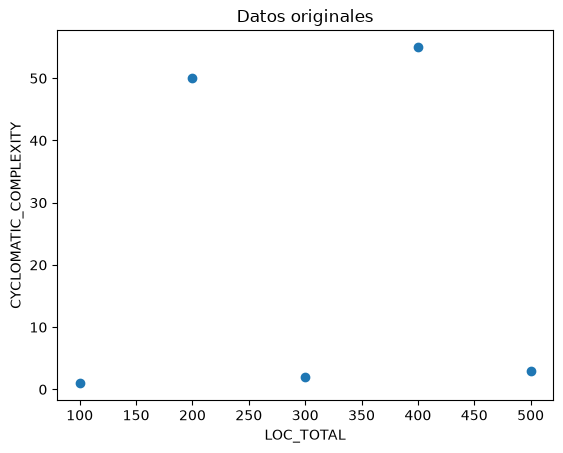

In [5]:
plt.scatter(
df["LOC_TOTAL"],
df["CYCLOMATIC_COMPLEXITY"]
)
plt.xlabel("LOC_TOTAL")
plt.ylabel("CYCLOMATIC_COMPLEXITY")
plt.title("Datos originales")
plt.show()

## Aplicar k-means y graficar sin escalar


In [8]:
kmeans = KMeans(
n_clusters=2,
random_state=42
)
df["Cluster"] = kmeans.fit_predict(
df[["LOC_TOTAL",
"CYCLOMATIC_COMPLEXITY"]]

)
print(df)

   LOC_TOTAL  CYCLOMATIC_COMPLEXITY  Cluster
0        100                      1        0
1        200                     50        0
2        300                      2        0
3        400                     55        1
4        500                      3        1


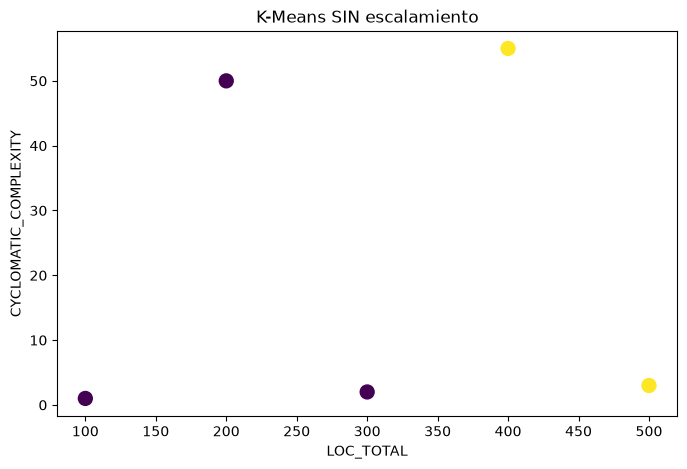

In [9]:
plt.figure(figsize=(8,5))
plt.scatter(
df["LOC_TOTAL"],
df["CYCLOMATIC_COMPLEXITY"],
c=df["Cluster"],
cmap="viridis",
s=100
)
plt.xlabel("LOC_TOTAL")
plt.ylabel("CYCLOMATIC_COMPLEXITY")
plt.title("K-Means SIN escalamiento")
plt.show()

## Aplicar k-means y graficar con escalar

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(
df[["LOC_TOTAL",
"CYCLOMATIC_COMPLEXITY"]]

)
scaled_df = pd.DataFrame(
X_scaled,
columns=[
"LOC_TOTAL",
"CYCLOMATIC_COMPLEXITY"
]
)
print(scaled_df)

   LOC_TOTAL  CYCLOMATIC_COMPLEXITY
0  -1.414214              -0.854894
1  -0.707107               1.121041
2   0.000000              -0.814569
3   0.707107               1.322667
4   1.414214              -0.774244


In [13]:
kmeans_scaled = KMeans(
n_clusters=2,
random_state=42
)

df["Cluster_scaled"] = kmeans_scaled.fit_predict(
X_scaled
)

print(df)

   LOC_TOTAL  CYCLOMATIC_COMPLEXITY  Cluster  Cluster_scaled
0        100                      1        0               0
1        200                     50        0               0
2        300                      2        0               1
3        400                     55        1               0
4        500                      3        1               1


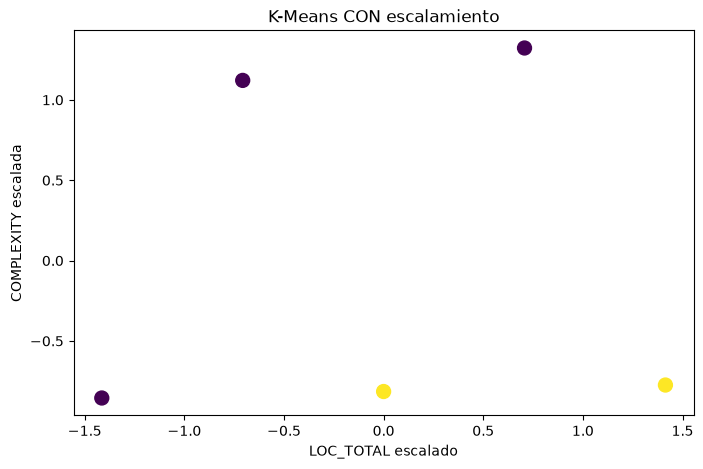

In [14]:
plt.figure(figsize=(8,5))
plt.scatter(
X_scaled[:,0],
X_scaled[:,1],
c=df["Cluster_scaled"],
cmap="viridis",
s=100
)
plt.xlabel("LOC_TOTAL escalado")
plt.ylabel("COMPLEXITY escalada")
plt.title("K-Means CON escalamiento")
plt.show()

## PREGUNTAS:

- ¿Qué cambió? Al escalar ambas variables, solo se transformaron a una media de cero y una desviación estándar de 1, pero, antes de escalar, LOC_TOTAL estaba predominando ya que sus valores eran mayores.

- ¿Ahora ambas variables tienen el mismo peso? Si, solo se estandarizó.

- ¿K-Means considera en la misma medida tanto tamaño como complejidad? K-Means utiliza la distancia euclidiana para determinar qué tan cerca está cada observación de los centroides.

- ¿Los centroides cambian? Si. Los centroides cambian porque cambian tanto la escala de los datos como la asignación de las observaciones a cada cluster.

- ¿Los grupos pueden cambiar significativamente? Si, aqui dos cambiaron:
    - Sin escalar:
        - (300, 2)  quedaba en el Cluster 0
        - (400, 55) quedaba en el Cluster 1
    - Despues de escalar:
        - (300, 2)  cambio en el Cluster 1
        - (400, 55) cambio en el Cluster 0